In [1]:
import torch
import torchvision
import sklearn

print("Notebook kernel is working.")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Notebook kernel is working.
PyTorch: 2.15.0+cu132
CUDA available: False


In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Works whether VS Code starts the notebook in the project root or notebooks/
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "notebooks").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
SPLITS_DIR = PROJECT_ROOT / "splits"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"

DATA_DIR.mkdir(exist_ok=True)
SPLITS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder:", DATA_DIR)

Project root: /home/alangmathew/csc4880/CSC-4880-ml-final-images
Data folder: /home/alangmathew/csc4880/CSC-4880-ml-final-images/data


In [3]:
dataset = EuroSAT(
    root=DATA_DIR,
    download=True
)

class_names = dataset.classes

print(f"Total images: {len(dataset)}")
print(f"Number of classes: {len(class_names)}")
print("Classes:", class_names)

image, label = dataset[0]
print("First image size:", image.size)
print("First image label:", class_names[label])

100.0%


Total images: 27000
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
First image size: (64, 64)
First image label: AnnualCrop


,class,image_count
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


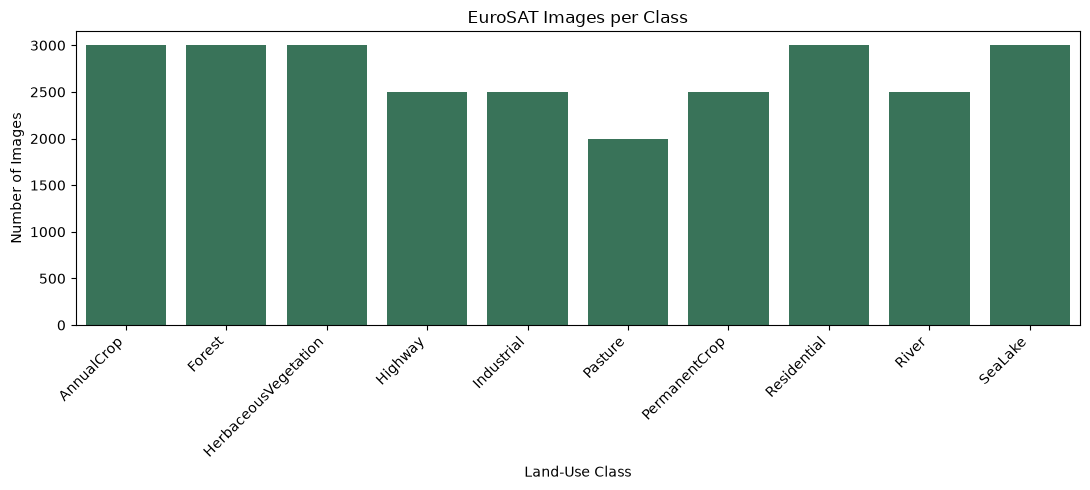

In [4]:
labels = np.array(dataset.targets)

class_counts = pd.Series(labels).value_counts().sort_index()

counts_df = pd.DataFrame({
    "class": class_names,
    "image_count": class_counts.values
})

display(counts_df)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=counts_df,
    x="class",
    y="image_count",
    color="#2f7d5a"
)

plt.title("EuroSAT Images per Class")
plt.xlabel("Land-Use Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "class_counts.png", dpi=300)
plt.show()

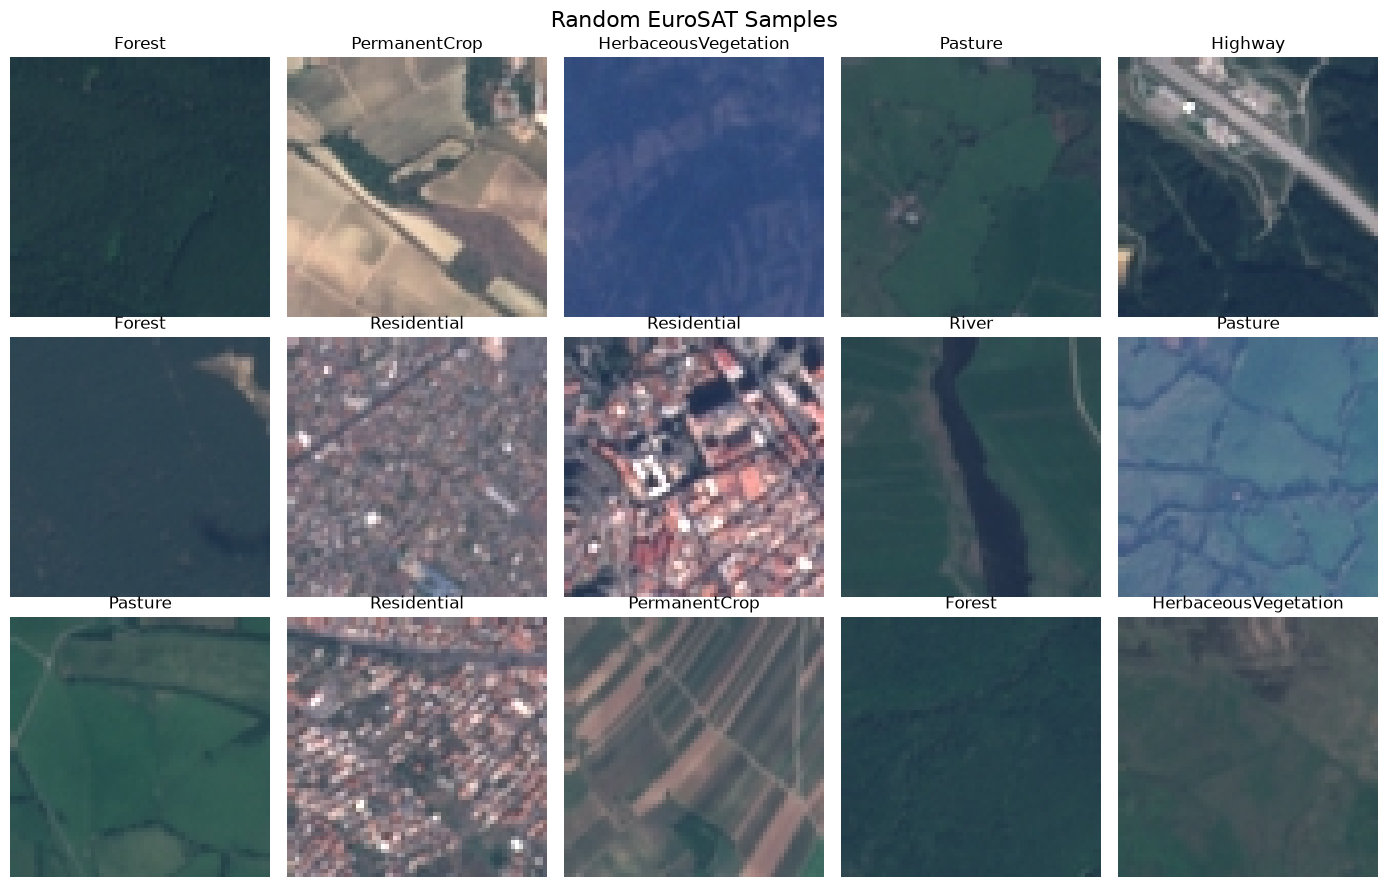

In [5]:
fig, axes = plt.subplots(3, 5, figsize=(14, 9))

sample_indices = np.random.choice(
    len(dataset),
    size=15,
    replace=False
)

for ax, idx in zip(axes.flat, sample_indices):
    image, label = dataset[idx]

    ax.imshow(image)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Random EuroSAT Samples", fontsize=16)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "sample_grid.png", dpi=300)
plt.show()

In [6]:
all_indices = np.arange(len(dataset))

# 70% train, 30% temporary
train_indices, temp_indices, train_labels, temp_labels = train_test_split(
    all_indices,
    labels,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Split the remaining 30% equally: 15% validation, 15% test
val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_labels
)

# Save the fixed split files
np.save(SPLITS_DIR / "train_indices.npy", train_indices)
np.save(SPLITS_DIR / "val_indices.npy", val_indices)
np.save(SPLITS_DIR / "test_indices.npy", test_indices)

print(f"Train images: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

Train images: 18900
Validation images: 4050
Test images: 4050


In [7]:
split_summary = pd.DataFrame({
    "class": class_names,
    "train": np.bincount(labels[train_indices], minlength=len(class_names)),
    "validation": np.bincount(labels[val_indices], minlength=len(class_names)),
    "test": np.bincount(labels[test_indices], minlength=len(class_names)),
})

display(split_summary)

,class,train,validation,test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2100,450,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450
